In [1]:
import pandas as pd
employee = pd.read_csv("employee.csv")
employee.head()

,Employee_ID,Age,Gender,Marital_Status,Department,Job_Role,Job_Level,Monthly_Income,Hourly_Rate,Years_at_Company,...,Overtime,Project_Count,Average_Hours_Worked_Per_Week,Absenteeism,Work_Environment_Satisfaction,Relationship_with_Manager,Job_Involvement,Distance_From_Home,Number_of_Companies_Worked,Attrition
0,1,58,Female,Married,IT,Manager,1,15488,28,15,...,No,6,54,17,4,4,4,20,3,No
1,2,48,Female,Married,Sales,Assistant,5,13079,28,6,...,Yes,2,45,1,4,1,2,25,2,No
2,3,34,Male,Married,Marketing,Assistant,1,13744,24,24,...,Yes,6,34,2,3,4,4,45,3,No
3,4,27,Female,Divorced,Marketing,Manager,1,6809,26,10,...,No,9,48,18,2,3,1,35,3,No
4,5,40,Male,Divorced,Marketing,Executive,1,10206,52,29,...,No,3,33,0,4,1,3,44,3,No


In [2]:
# Menampilkan ringkasan informasi dari dataset
employee.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 26 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   Employee_ID                    1500 non-null   int64
 1   Age                            1500 non-null   int64
 2   Gender                         1500 non-null   str  
 3   Marital_Status                 1500 non-null   str  
 4   Department                     1500 non-null   str  
 5   Job_Role                       1500 non-null   str  
 6   Job_Level                      1500 non-null   int64
 7   Monthly_Income                 1500 non-null   int64
 8   Hourly_Rate                    1500 non-null   int64
 9   Years_at_Company               1500 non-null   int64
 10  Years_in_Current_Role          1500 non-null   int64
 11  Years_Since_Last_Promotion     1500 non-null   int64
 12  Work_Life_Balance              1500 non-null   int64
 13  Job_Satisfaction             

In [3]:
# Menampilkan statistik deskriptif dari dataset
employee.describe(include="all")

,Employee_ID,Age,Gender,Marital_Status,Department,Job_Role,Job_Level,Monthly_Income,Hourly_Rate,Years_at_Company,...,Overtime,Project_Count,Average_Hours_Worked_Per_Week,Absenteeism,Work_Environment_Satisfaction,Relationship_with_Manager,Job_Involvement,Distance_From_Home,Number_of_Companies_Worked,Attrition
count,1500.000000,1500.000000,1500,1500,1500,1500,1500.000000,1500.000000,1500.000000,1500.000000,...,1500,1500.000000,1500.000000,1500.000000,1500.00000,1500.000000,1500.000000,1500.000000,1500.000000,1500
unique,NaN,NaN,2,3,5,4,NaN,NaN,NaN,NaN,...,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,NaN,NaN,Male,Married,Finance,Manager,NaN,NaN,NaN,NaN,...,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No
freq,NaN,NaN,761,532,338,415,NaN,NaN,NaN,NaN,...,776,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1203
mean,750.500000,39.789333,NaN,NaN,NaN,NaN,3.052667,11605.540000,57.478667,14.878667,...,NaN,4.888000,44.410667,9.634000,2.47400,2.493333,2.488000,24.262667,2.468667,NaN
std,433.157015,11.709670,NaN,NaN,NaN,NaN,1.396851,4881.361846,24.943730,8.263179,...,NaN,2.545802,8.775270,6.061177,1.11392,1.103978,1.100301,14.001251,1.101738,NaN
min,1.000000,20.000000,NaN,NaN,NaN,NaN,1.000000,3001.000000,15.000000,1.000000,...,NaN,1.000000,30.000000,0.000000,1.00000,1.000000,1.000000,1.000000,1.000000,NaN
25%,375.750000,29.000000,NaN,NaN,NaN,NaN,2.000000,7586.500000,35.000000,8.000000,...,NaN,3.000000,37.000000,4.000000,1.75000,2.000000,2.000000,12.000000,1.750000,NaN
50%,750.500000,41.000000,NaN,NaN,NaN,NaN,3.000000,11514.000000,58.000000,15.000000,...,NaN,5.000000,44.000000,9.000000,2.00000,2.000000,3.000000,23.000000,2.000000,NaN
75%,1125.250000,50.000000,NaN,NaN,NaN,NaN,4.000000,15855.000000,79.000000,22.000000,...,NaN,7.000000,52.000000,15.000000,3.00000,3.000000,3.000000,36.000000,3.000000,NaN


In [4]:
# Memeriksa jumlah nilai yang hilang di setiap kolom
missing_values = employee.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

In [5]:
# Berdasarkan pengecekan employee.isnull().sum() tidak ditemukan missing values, 
# sehingga tahap imputasi median tidak diperlukan dan langsung dilanjutkan ke pengecekan outliers

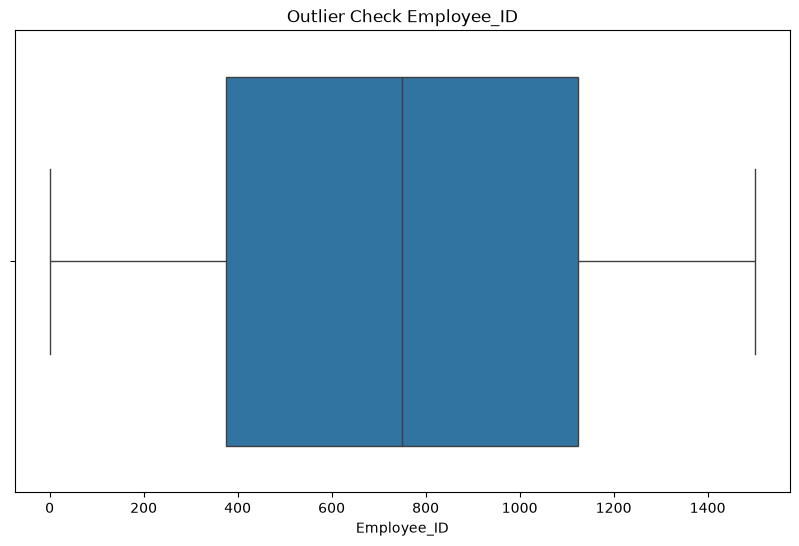

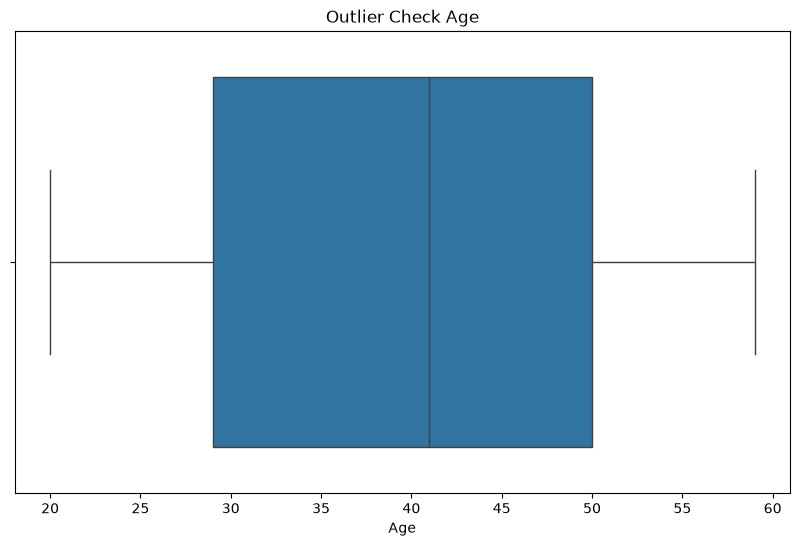

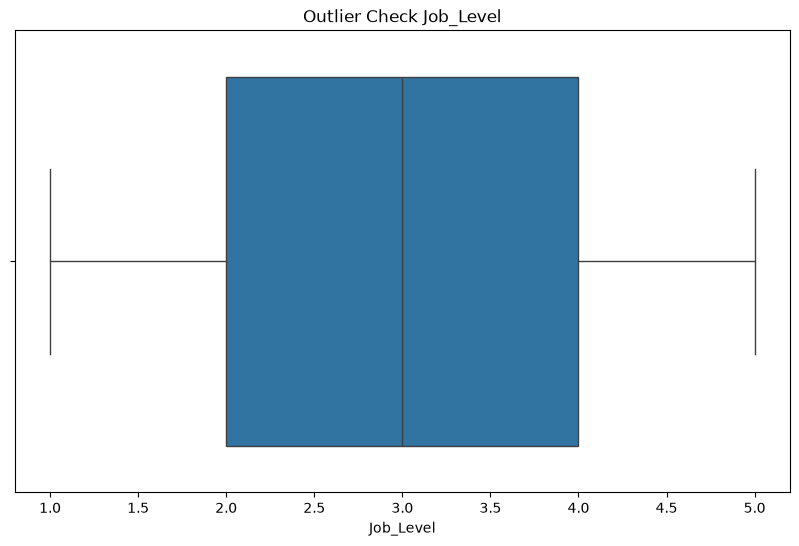

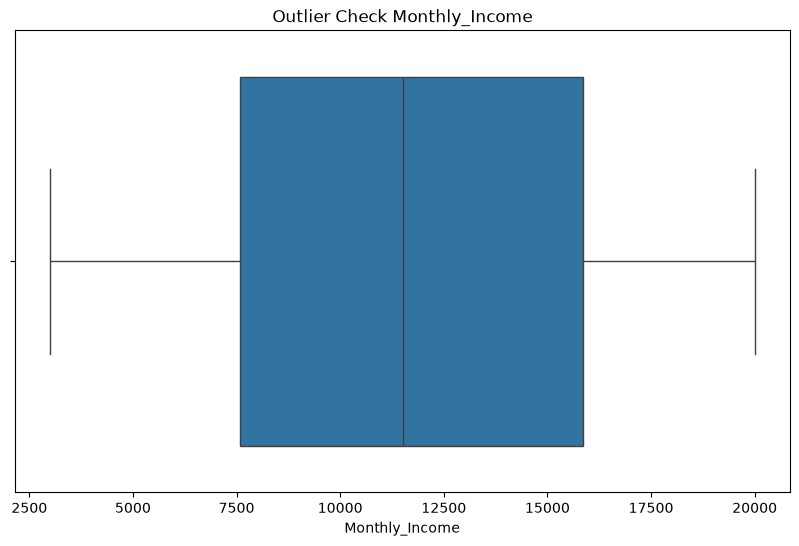

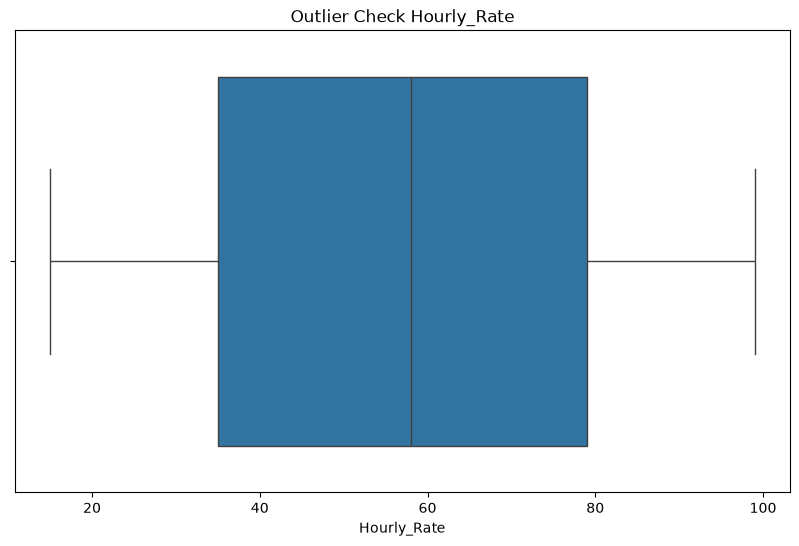

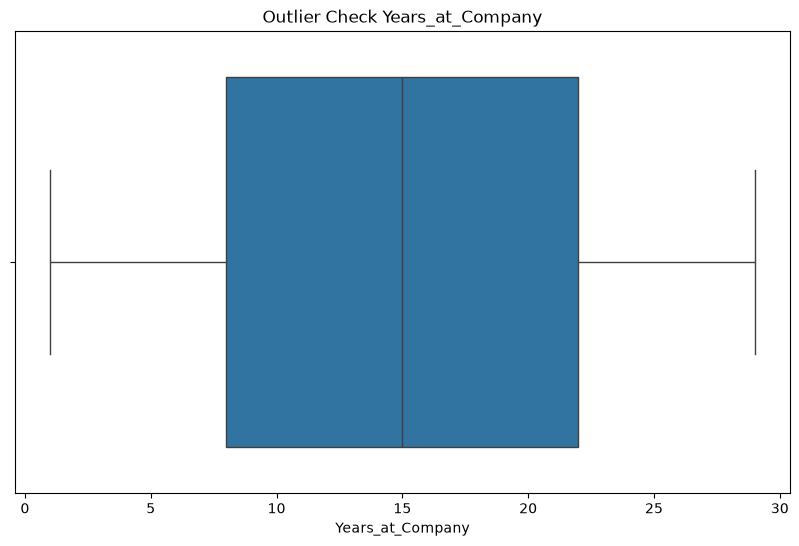

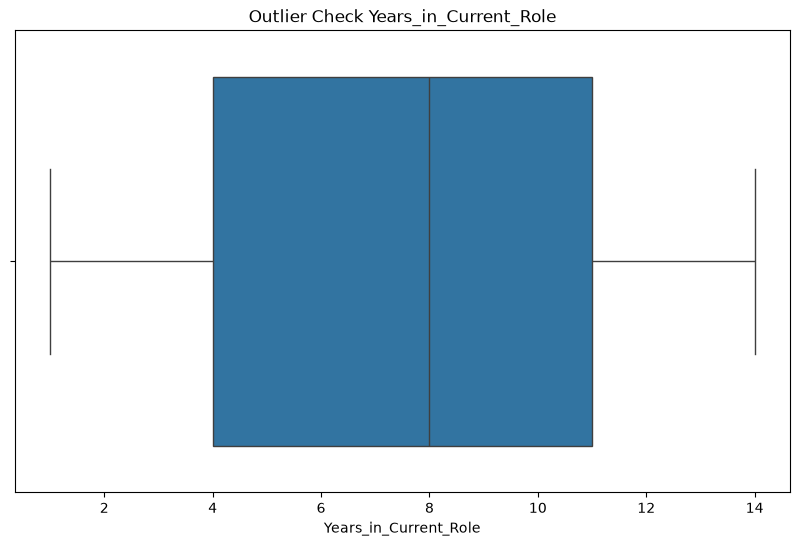

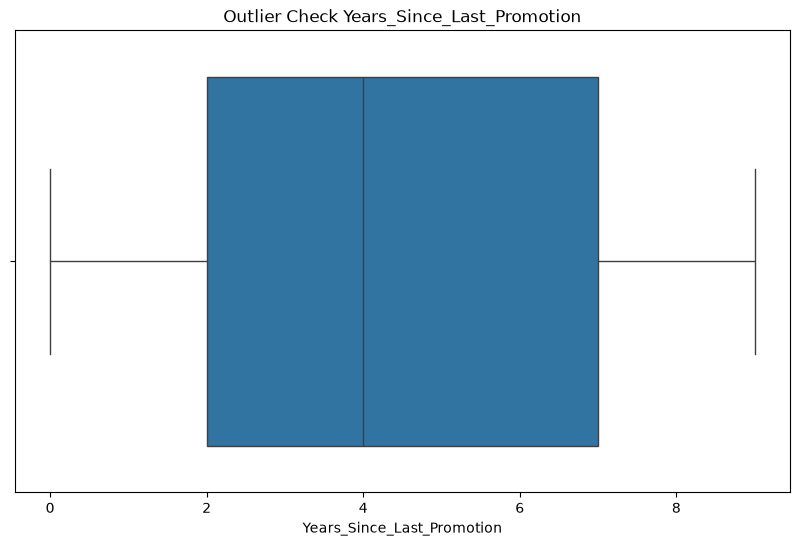

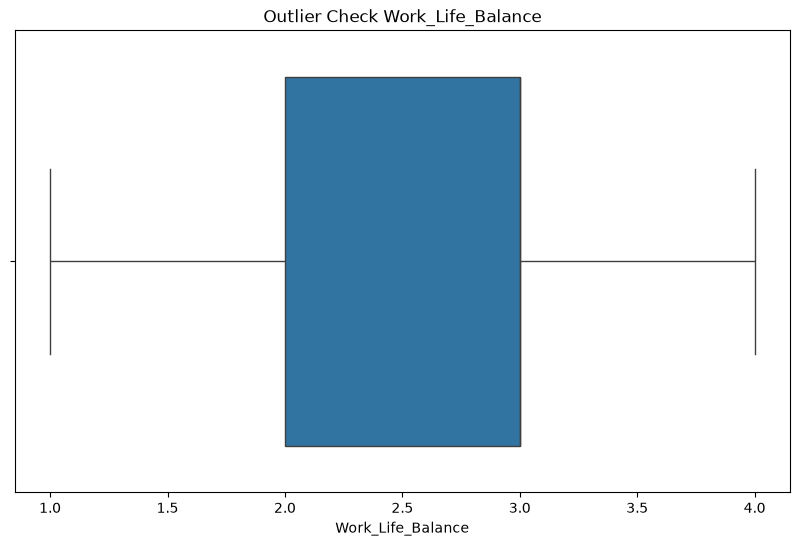

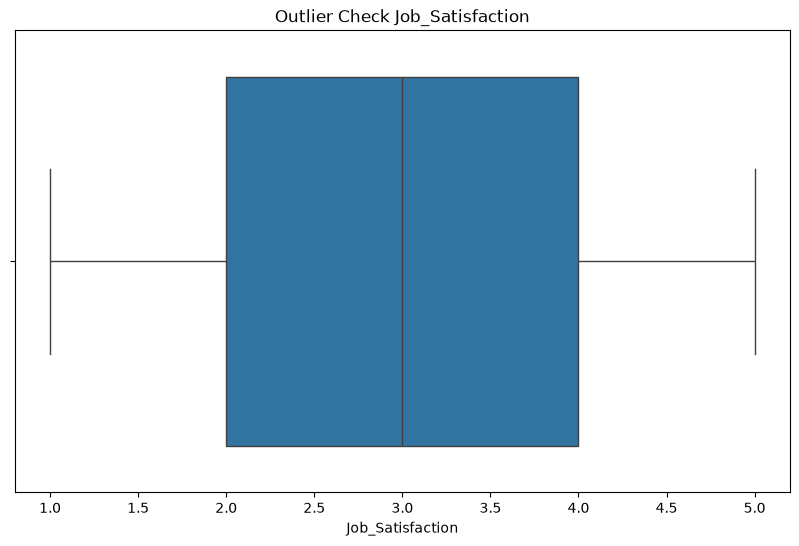

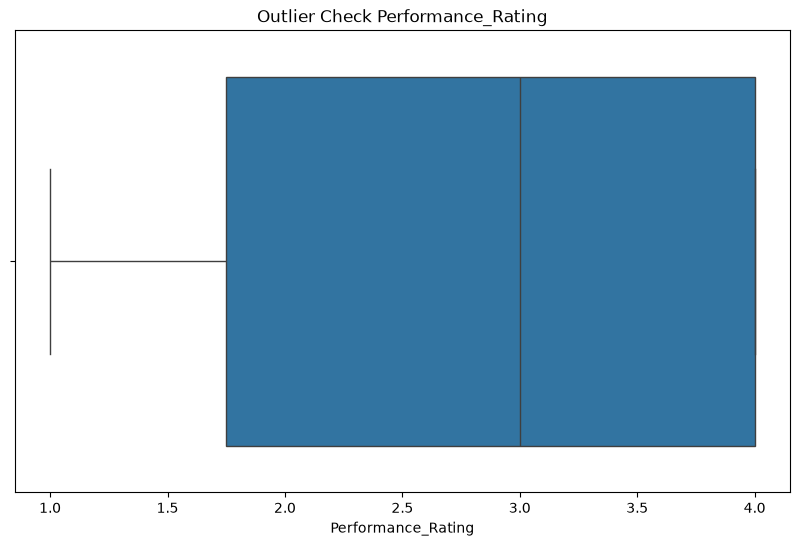

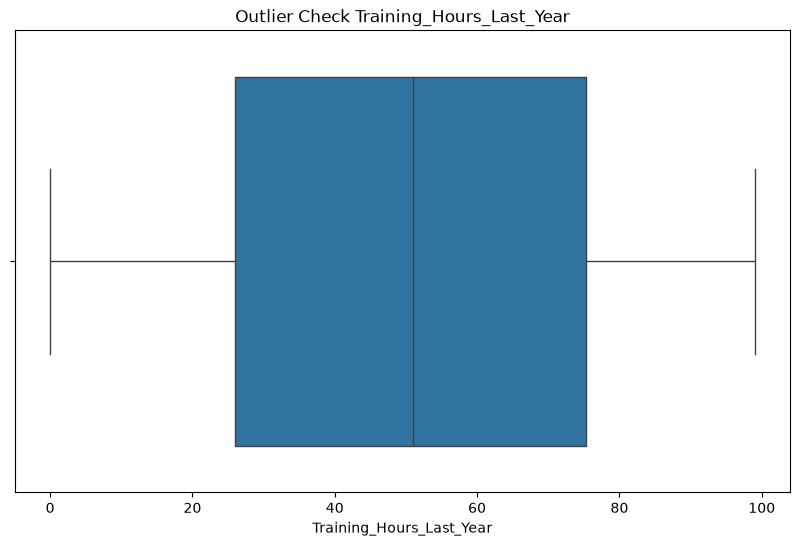

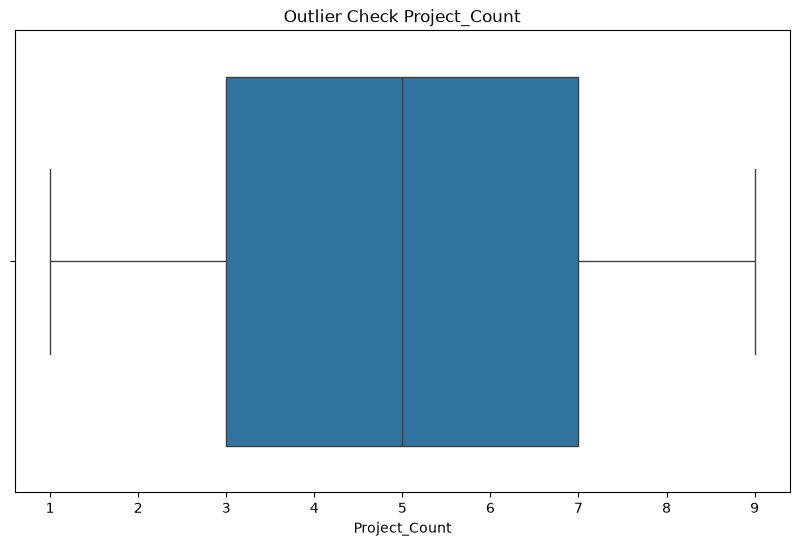

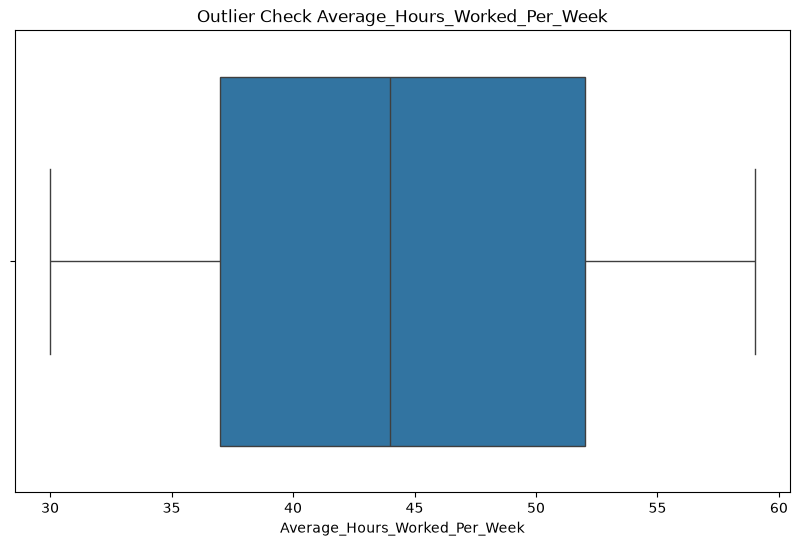

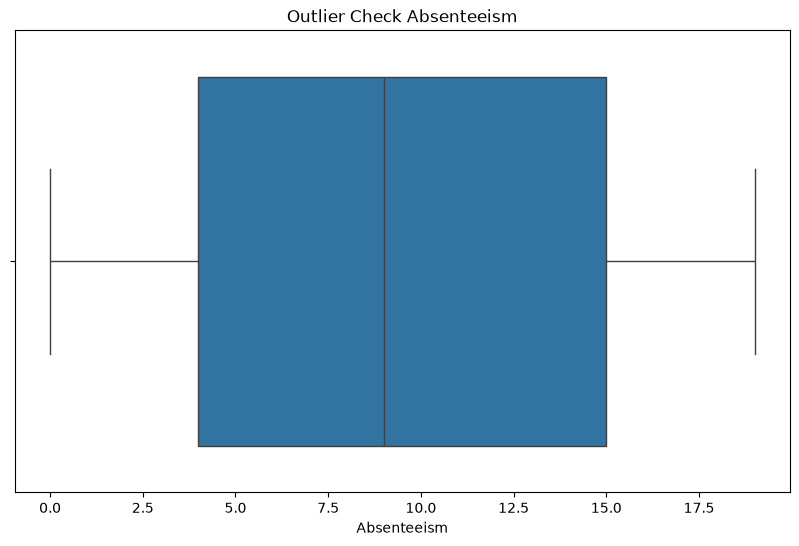

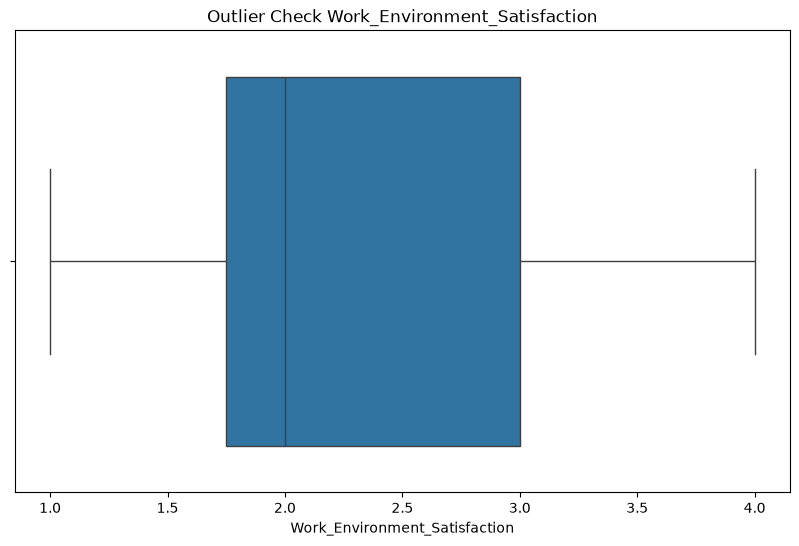

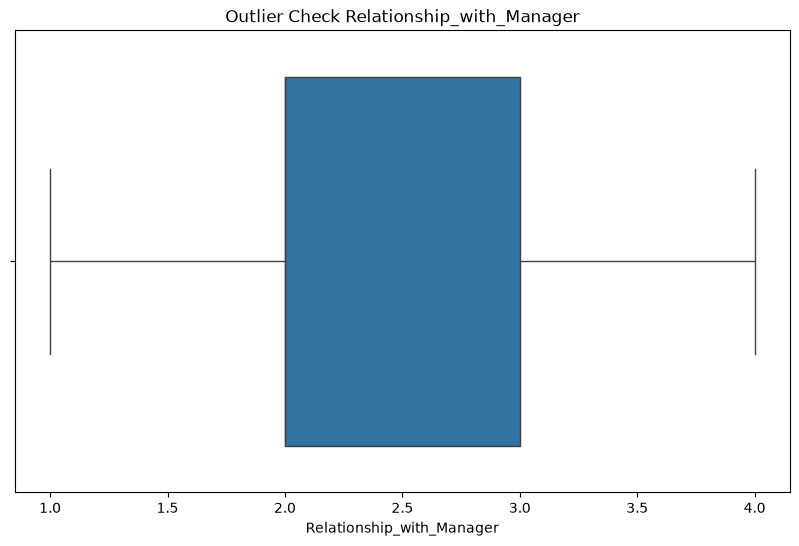

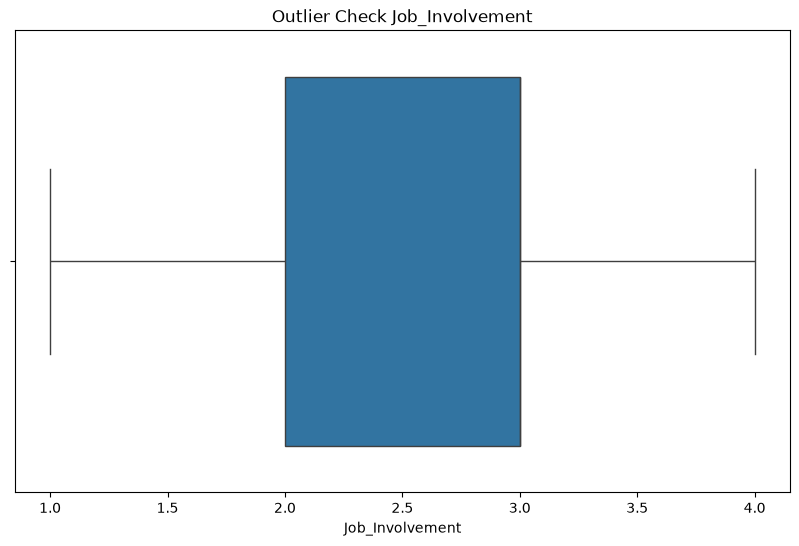

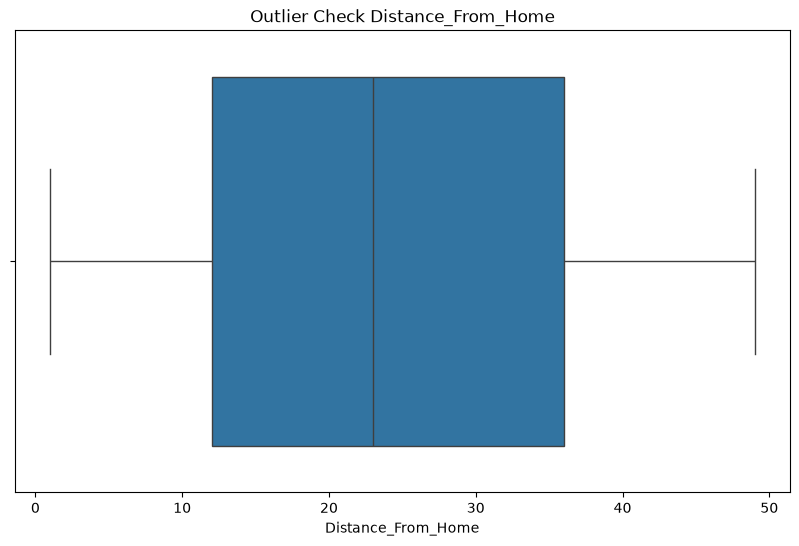

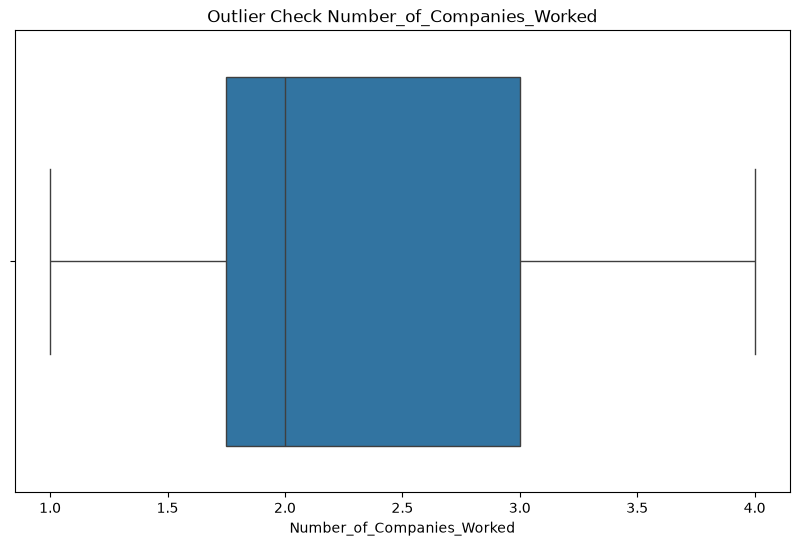

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_features = employee.select_dtypes(include=['int64','float64']).columns

for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=employee[feature])
    plt.title(f'Outlier Check {feature}')
    plt.show()

In [7]:
df = employee

In [8]:
# Contoh sederhana untuk mengidentifikasi outliers menggunakan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [9]:
# Filter dataframe untuk hanya menyimpan baris yang tidak mengandung outliers pada kolom numerik
condition = ~((df[numeric_features] < (Q1 - 1.5 * IQR)) | (df[numeric_features] > (Q3 + 1.5 * IQR))).any(axis=1)
df_filtered_numeric = df.loc[condition, numeric_features]
    
# Menggabungkan kembali dengan kolom kategorikal
categorical_features = df.select_dtypes(include=['object']).columns
df = pd.concat([df_filtered_numeric, df.loc[condition, categorical_features]], axis=1)

C:\Users\marve\AppData\Local\Temp\ipykernel_25712\4234585303.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include=['object']).columns


Text(0.5, 1.0, 'Histogram Sebelum Standardisasi')

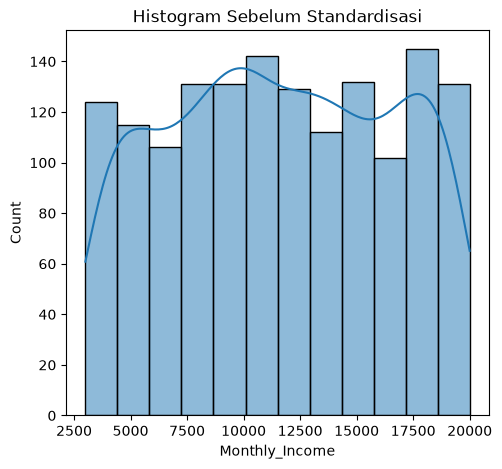

In [10]:
# Histogram Sebelum Standardisasi
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 2)
sns.histplot(df['Monthly_Income'], kde=True)
plt.title("Histogram Sebelum Standardisasi")

In [11]:
from sklearn.preprocessing import StandardScaler

# Standardisasi fitur numerik
scaler = StandardScaler()
df['Monthly_Income'] = scaler.fit_transform(df[['Monthly_Income']])

Text(0.5, 1.0, 'Histogram Setelah Standardisasi')

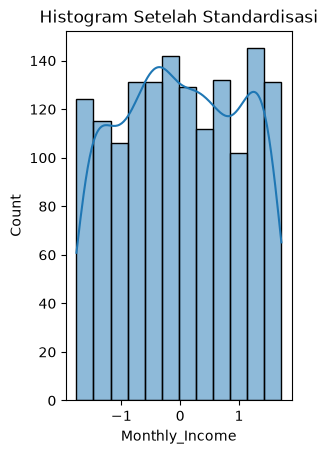

In [12]:
# Histogram Setelah Standardisasi
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[3]], kde=True)
plt.title("Histogram Setelah Standardisasi")

In [13]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()

print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
Empty DataFrame
Columns: [Employee_ID, Age, Job_Level, Monthly_Income, Hourly_Rate, Years_at_Company, Years_in_Current_Role, Years_Since_Last_Promotion, Work_Life_Balance, Job_Satisfaction, Performance_Rating, Training_Hours_Last_Year, Project_Count, Average_Hours_Worked_Per_Week, Absenteeism, Work_Environment_Satisfaction, Relationship_with_Manager, Job_Involvement, Distance_From_Home, Number_of_Companies_Worked, Gender, Marital_Status, Department, Job_Role, Overtime, Attrition]
Index: []

[0 rows x 26 columns]


In [14]:
category_features = df.select_dtypes(include=['object']).columns
df[category_features]

C:\Users\marve\AppData\Local\Temp\ipykernel_25712\2319133481.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  category_features = df.select_dtypes(include=['object']).columns


,Gender,Marital_Status,Department,Job_Role,Overtime,Attrition
0,Female,Married,IT,Manager,No,No
1,Female,Married,Sales,Assistant,Yes,No
2,Male,Married,Marketing,Assistant,Yes,No
3,Female,Divorced,Marketing,Manager,No,No
4,Male,Divorced,Marketing,Executive,No,No
...,...,...,...,...,...,...
1495,Male,Married,Finance,Analyst,Yes,No
1496,Male,Married,IT,Assistant,Yes,No
1497,Female,Divorced,Marketing,Assistant,Yes,No
1498,Female,Married,Sales,Manager,Yes,No


In [15]:
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot

,Employee_ID,Age,Job_Level,Monthly_Income,Hourly_Rate,Years_at_Company,Years_in_Current_Role,Years_Since_Last_Promotion,Work_Life_Balance,Job_Satisfaction,...,Department_Marketing,Department_Sales,Job_Role_Analyst,Job_Role_Assistant,Job_Role_Executive,Job_Role_Manager,Overtime_No,Overtime_Yes,Attrition_No,Attrition_Yes
0,1,58,1,0.795629,28,15,4,2,1,3,...,False,False,False,False,False,True,True,False,True,False
1,2,48,5,0.301955,28,6,9,1,2,1,...,False,True,False,True,False,False,False,True,True,False
2,3,34,1,0.438233,24,24,14,8,3,2,...,True,False,False,True,False,False,False,True,True,False
3,4,27,1,-0.982951,26,10,8,2,3,5,...,True,False,False,False,False,True,True,False,True,False
4,5,40,1,-0.286807,52,29,10,1,2,5,...,True,False,False,False,True,False,True,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1495,1496,43,1,1.651209,99,3,14,7,1,4,...,False,False,True,False,False,False,False,True,True,False
1496,1497,22,5,-1.382153,22,8,14,9,1,4,...,False,False,False,True,False,False,False,True,True,False
1497,1498,24,2,0.735995,77,2,4,0,1,5,...,True,False,False,True,False,False,False,True,True,False
1498,1499,44,3,1.494233,62,24,12,1,4,5,...,False,True,False,False,False,True,False,True,True,False


In [16]:
from sklearn.preprocessing import LabelEncoder

# Inisialisasi LabelEncoder
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])
# Menampilkan hasil
df_lencoder

,Employee_ID,Age,Job_Level,Monthly_Income,Hourly_Rate,Years_at_Company,Years_in_Current_Role,Years_Since_Last_Promotion,Work_Life_Balance,Job_Satisfaction,...,Relationship_with_Manager,Job_Involvement,Distance_From_Home,Number_of_Companies_Worked,Gender,Marital_Status,Department,Job_Role,Overtime,Attrition
0,1,58,1,0.795629,28,15,4,2,1,3,...,4,4,20,3,0,1,2,3,0,0
1,2,48,5,0.301955,28,6,9,1,2,1,...,1,2,25,2,0,1,4,1,1,0
2,3,34,1,0.438233,24,24,14,8,3,2,...,4,4,45,3,1,1,3,1,1,0
3,4,27,1,-0.982951,26,10,8,2,3,5,...,3,1,35,3,0,0,3,3,0,0
4,5,40,1,-0.286807,52,29,10,1,2,5,...,1,3,44,3,1,0,3,2,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1495,1496,43,1,1.651209,99,3,14,7,1,4,...,4,1,44,4,1,1,0,0,1,0
1496,1497,22,5,-1.382153,22,8,14,9,1,4,...,1,3,7,4,1,1,2,1,1,0
1497,1498,24,2,0.735995,77,2,4,0,1,5,...,1,4,40,3,0,0,3,1,1,0
1498,1499,44,3,1.494233,62,24,12,1,4,5,...,2,1,17,1,0,1,4,3,1,0


In [17]:
df_lencoder.head()

,Employee_ID,Age,Job_Level,Monthly_Income,Hourly_Rate,Years_at_Company,Years_in_Current_Role,Years_Since_Last_Promotion,Work_Life_Balance,Job_Satisfaction,...,Relationship_with_Manager,Job_Involvement,Distance_From_Home,Number_of_Companies_Worked,Gender,Marital_Status,Department,Job_Role,Overtime,Attrition
0,1,58,1,0.795629,28,15,4,2,1,3,...,4,4,20,3,0,1,2,3,0,0
1,2,48,5,0.301955,28,6,9,1,2,1,...,1,2,25,2,0,1,4,1,1,0
2,3,34,1,0.438233,24,24,14,8,3,2,...,4,4,45,3,1,1,3,1,1,0
3,4,27,1,-0.982951,26,10,8,2,3,5,...,3,1,35,3,0,0,3,3,0,0
4,5,40,1,-0.286807,52,29,10,1,2,5,...,1,3,44,3,1,0,3,2,0,0


In [18]:
# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100

missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

missing_data[missing_data['Missing Values'] > 0] # Menampilkan kolom dengan missing values

,Missing Values,Percentage


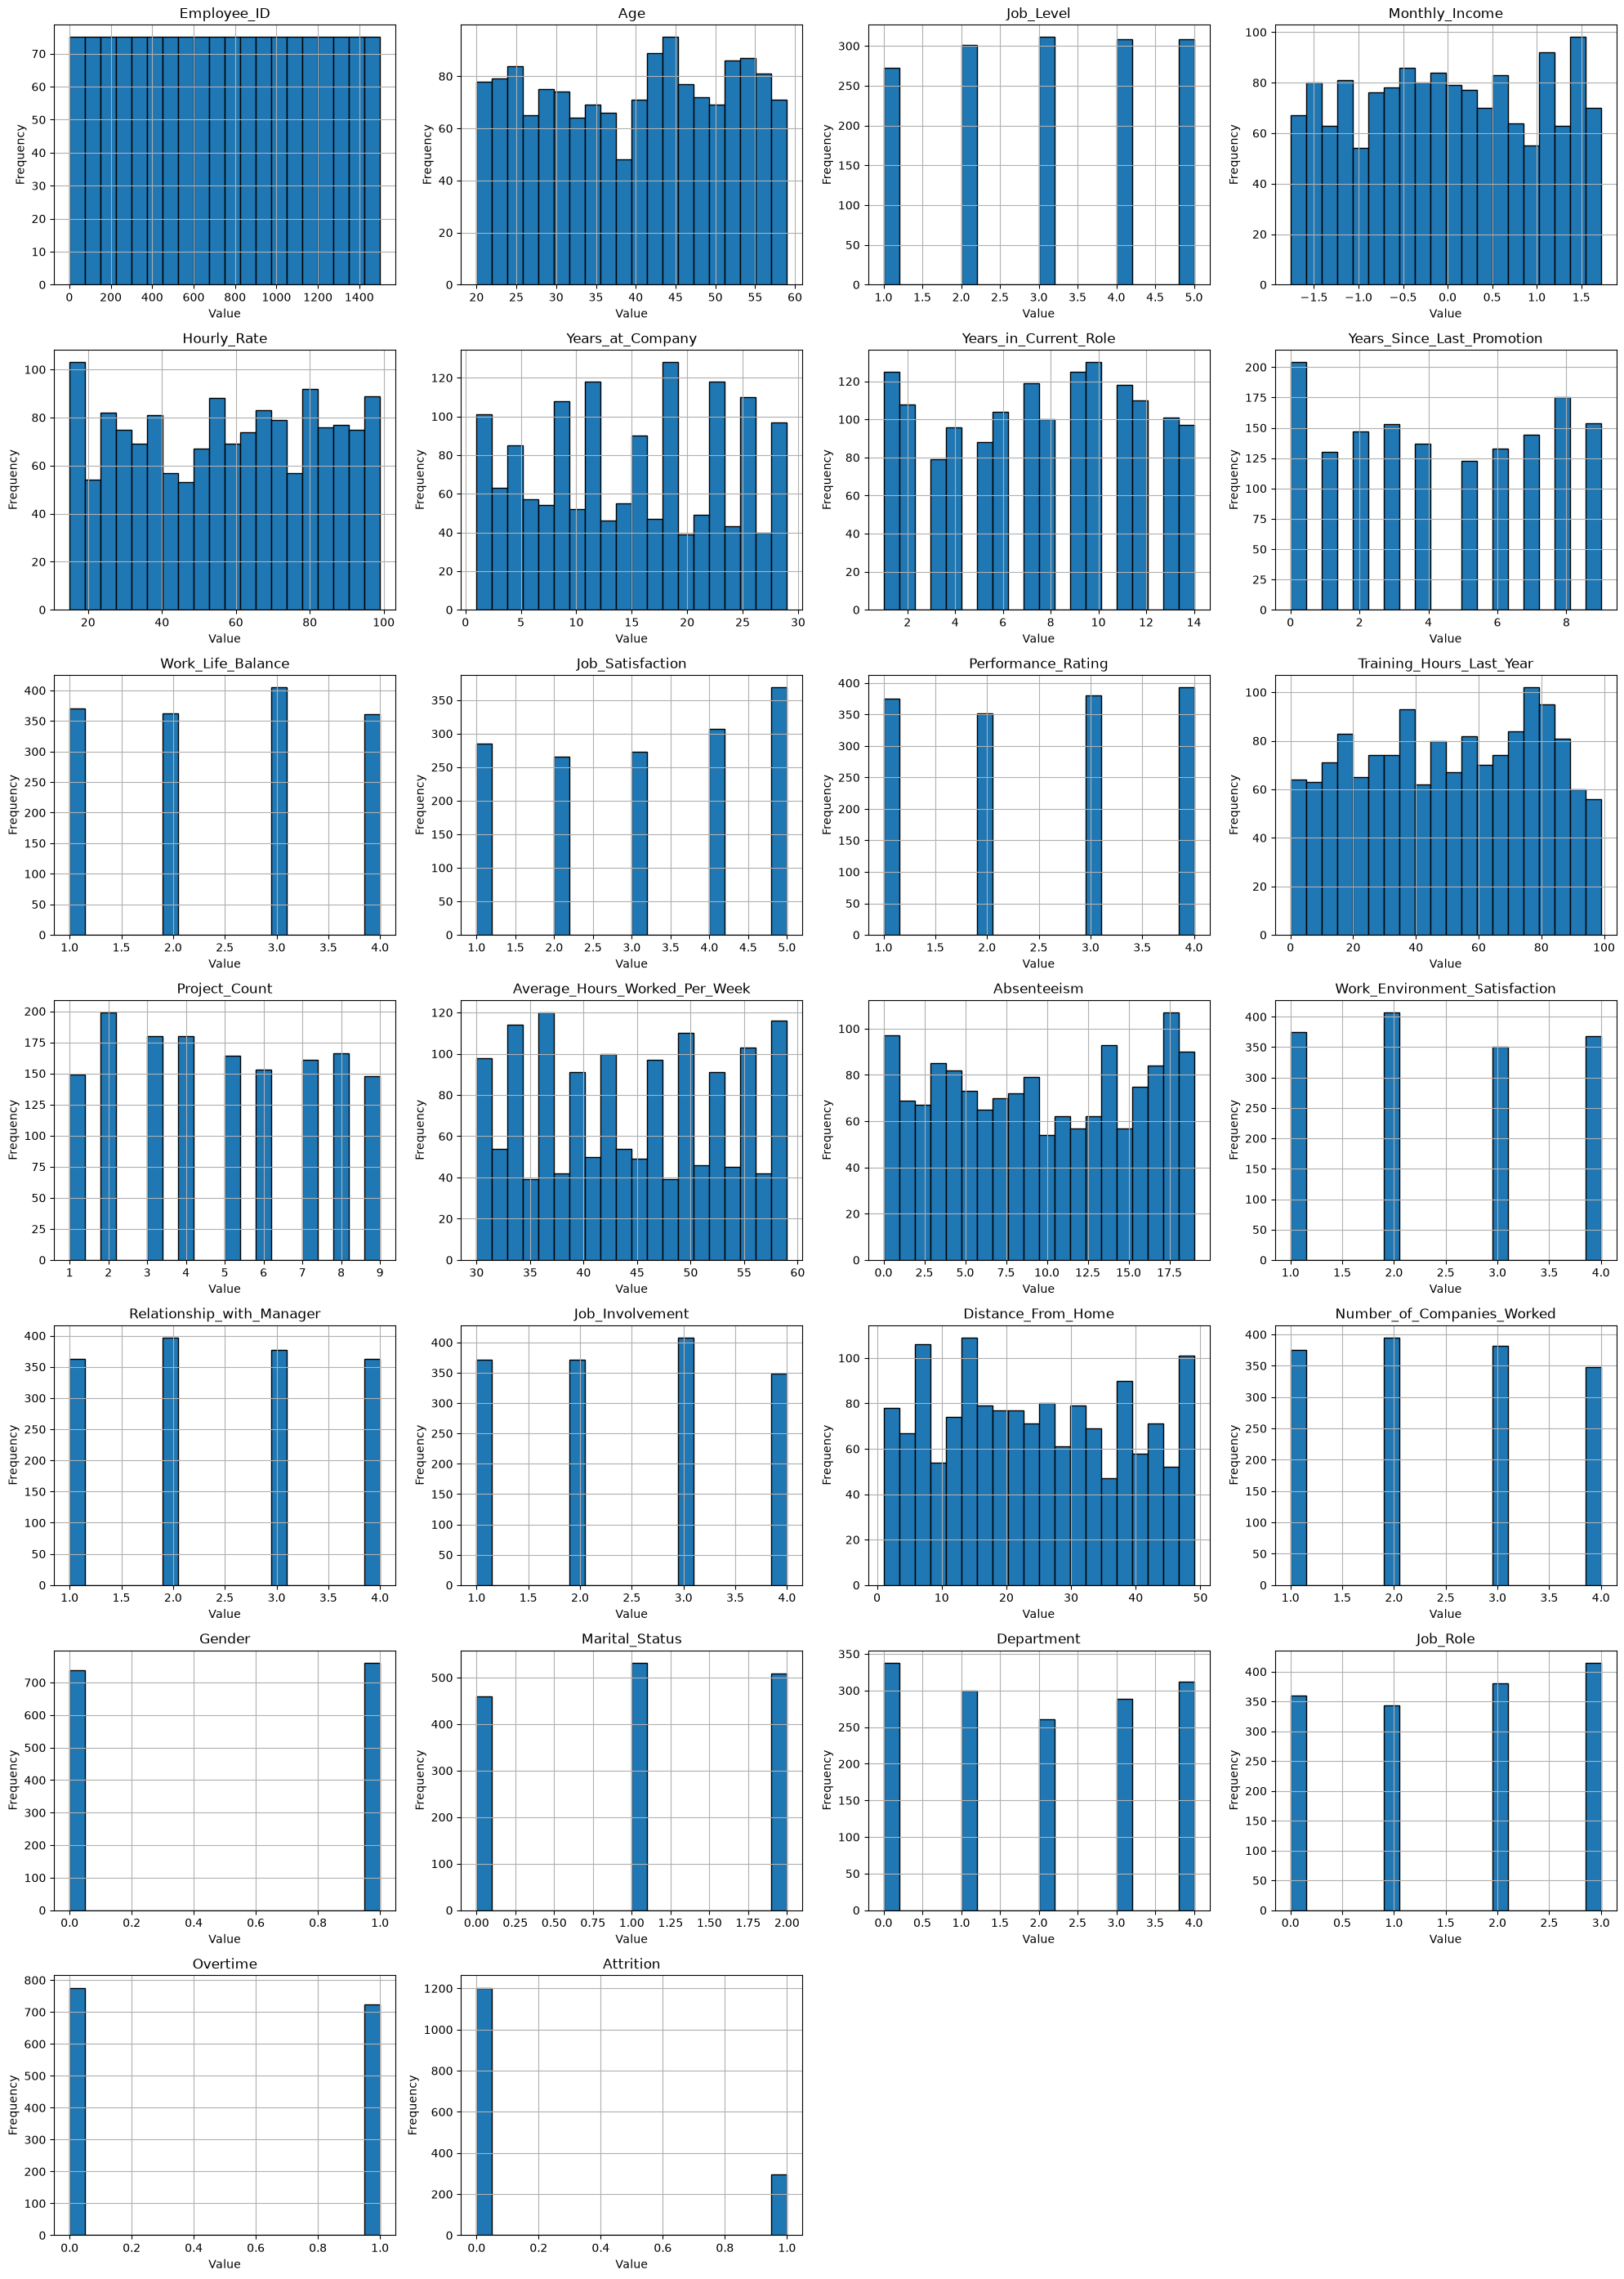

In [19]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]

# Menentukan jumlah baris dan kolom untuk grid subplot
n_cols = 4 # Jumlah kolom yang diinginkan
n_rows = -(-num_vars // n_cols) # Ceiling division untuk menentukan jumlah baris

# Membuat subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))

# Flatten axes array untuk memudahkan iterasi jika diperlukan
axes = axes.flatten()

# Plot setiap variabel
for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Menghapus subplot yang tidak terpakai (jika ada)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Menyesuaikan layout agar lebih rapi
plt.tight_layout()
plt.show()

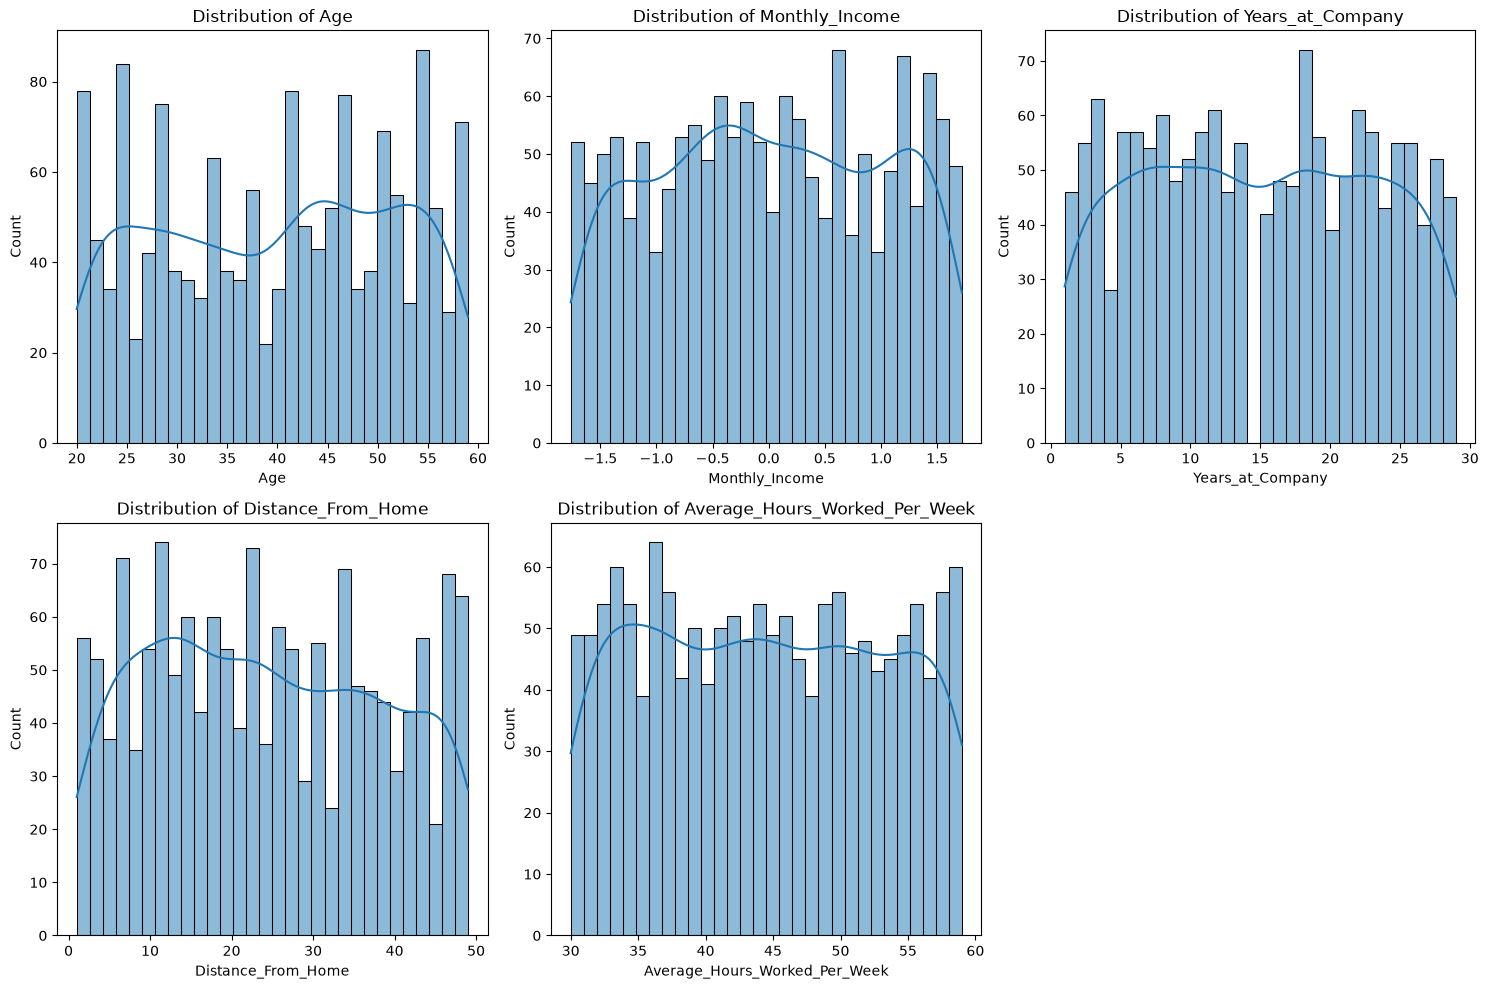

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualisasi distribusi data untuk beberapa kolom
columns_to_plot = ['Age', 'Monthly_Income', 'Years_at_Company', 'Distance_From_Home', 'Average_Hours_Worked_Per_Week']

plt.figure(figsize=(15, 10))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_lencoder[column], kde=True, bins=30)
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

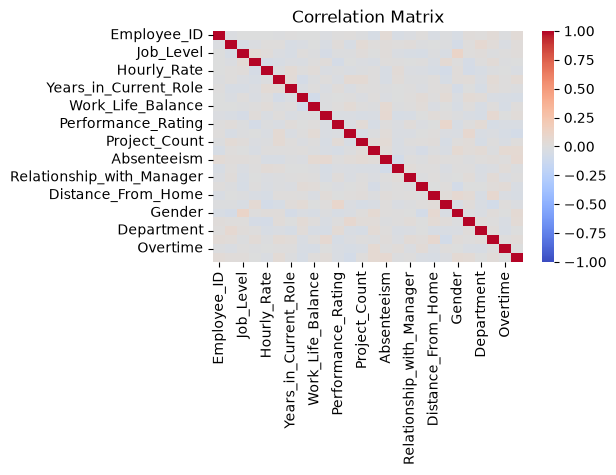

In [21]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(5, 3))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

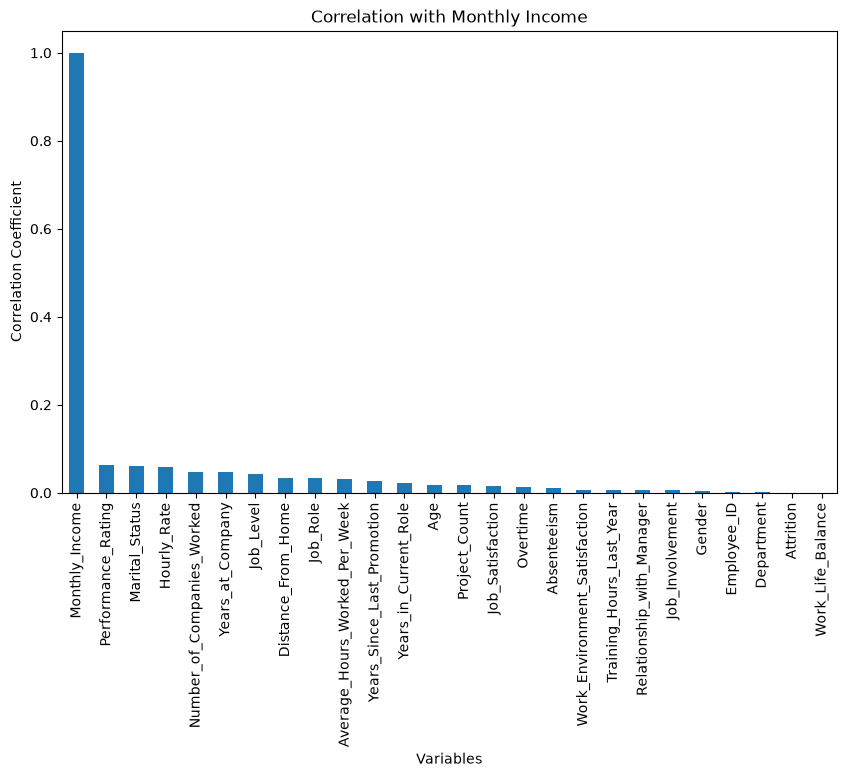

Monthly_Income                   1.000000
Performance_Rating               0.062778
Marital_Status                   0.061188
Hourly_Rate                      0.058545
Number_of_Companies_Worked       0.047012
Years_at_Company                 0.046770
Job_Level                        0.042872
Distance_From_Home               0.034624
Job_Role                         0.033476
Average_Hours_Worked_Per_Week    0.032266
Years_Since_Last_Promotion       0.027954
Years_in_Current_Role            0.022558
Age                              0.017808
Project_Count                    0.017102
Job_Satisfaction                 0.015873
Overtime                         0.013206
Absenteeism                      0.011606
Work_Environment_Satisfaction    0.006894
Training_Hours_Last_Year         0.005835
Relationship_with_Manager        0.005623
Job_Involvement                  0.005332
Gender                           0.004334
Employee_ID                      0.001870
Department                       0

In [22]:
# Menghitung korelasi antara variabel target dan semua variabel lainnya
target_corr = df_lencoder.corr()['Monthly_Income']

# (Opsional) Mengurutkan hasil korelasi
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind='bar')
plt.title(f'Correlation with Monthly Income')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.show()

print(target_corr_sorted)

In [23]:
# Memisahkan fitur (X) dan target (y)
X = df_lencoder.drop(columns=['Monthly_Income'])
y = df_lencoder['Monthly_Income']

from sklearn.model_selection import train_test_split

# membagi dataset menjadi training dan testing 
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=184)

In [24]:
# menghitung panjang/jumlah data 
print("Jumlah data: ",len(X))
# menghitung panjang/jumlah data pada x_train
print("Jumlah data latih: ",len(x_train))
# menghitung panjang/jumlah data pada x_test
print("Jumlah data test: ",len(x_test))

Jumlah data:  1500
Jumlah data latih:  1200
Jumlah data test:  300


In [25]:
# Melatih model 1 dengan algoritma Least Angle Regression
from sklearn import linear_model
lars = linear_model.Lars(n_nonzero_coefs=1)
lars.fit(x_train, y_train)

# Melatih model 2 dengan algoritma Linear Regression
from sklearn.linear_model import LinearRegression
LR = LinearRegression()
LR.fit(x_train, y_train)

# Melatih model 3 dengan algoritma Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor
GBR = GradientBoostingRegressor(random_state=184)
GBR.fit(x_train, y_train)

print("3 Model berhasil dilatih dengan Monthly Income")

3 Model berhasil dilatih dengan Monthly Income


In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluasi pada model LARS
pred_lars = lars.predict(x_test)
mae_lars = mean_absolute_error(y_test, pred_lars)
mse_lars = mean_squared_error(y_test, pred_lars)
r2_lars = r2_score(y_test, pred_lars)

# Membuat dictionary untuk menyimpan hasil evaluasi
data = {
    'MAE': [mae_lars],
    'MSE': [mse_lars],
    'R2': [r2_lars]
}

# Konversi dictionary menjadi DataFrame
df_results = pd.DataFrame(data, index=['Lars'])
df_results

,MAE,MSE,R2
Lars,0.856681,0.99112,-0.008373


In [27]:
# Evaluasi pada model Linear Regression
pred_LR = LR.predict(x_test)
mae_LR = mean_absolute_error(y_test, pred_LR)
mse_LR = mean_squared_error(y_test, pred_LR)
r2_LR = r2_score(y_test, pred_LR)

# Menambahkan hasil evaluasi LR ke DataFrame
df_results.loc['Linear Regression'] = [mae_LR, mse_LR, r2_LR]
df_results

,MAE,MSE,R2
Lars,0.856681,0.991120,-0.008373
Linear Regression,0.849981,0.985157,-0.002306


In [28]:
# Evaluasi pada model Gradient Boosting Regressor
pred_GBR = GBR.predict(x_test)
mae_GBR = mean_absolute_error(y_test, pred_GBR)
mse_GBR = mean_squared_error(y_test, pred_GBR)
r2_GBR = r2_score(y_test, pred_GBR)

# Menambahkan hasil evaluasi GBR ke DataFrame
df_results.loc['GradientBoostingRegressor'] = [mae_GBR, mse_GBR, r2_GBR]
df_results

,MAE,MSE,R2
Lars,0.856681,0.991120,-0.008373
Linear Regression,0.849981,0.985157,-0.002306
GradientBoostingRegressor,0.757624,0.819118,0.166623


In [29]:
import joblib

# Menyimpan model ke dalam file
joblib.dump(GBR, 'gbr_model_monthly_income.joblib')
print("Model disimpan sebagai gbr_model_monthly_income.joblib")

Model disimpan sebagai gbr_model_monthly_income.joblib
